[OK] Simulation 2 figure saved to: figures/sim2_quadrature_phase_space.png


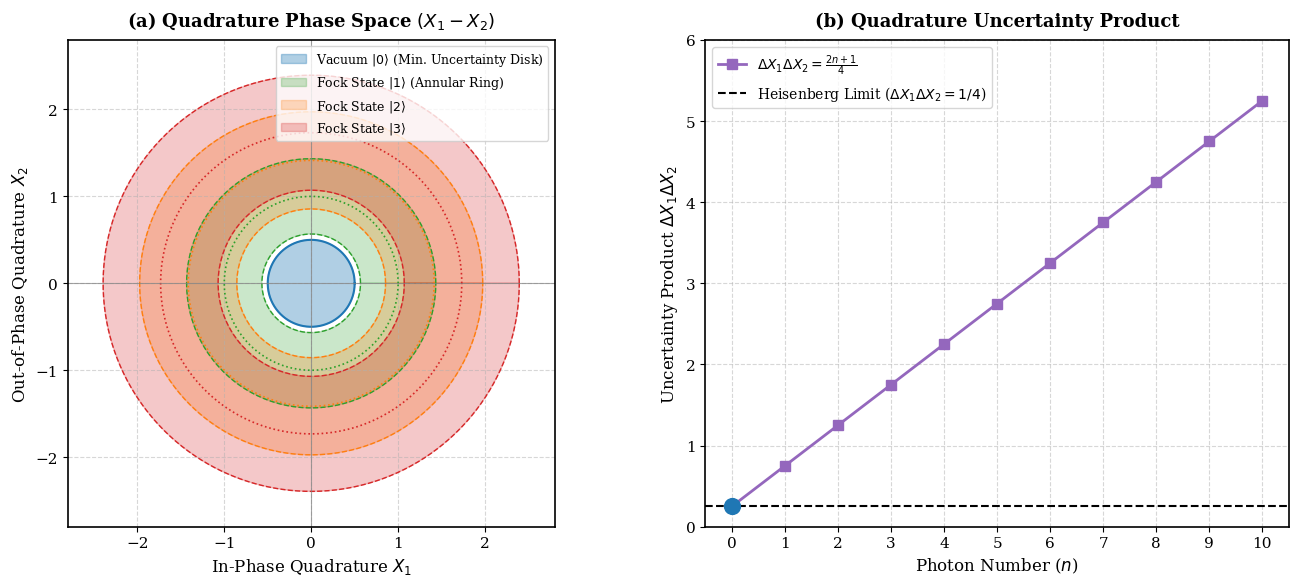

In [9]:
# ==============================================================================
# Simulation 2: Quadrature Operators & Phase Space Uncertainty Disks
# Reference: Gerry & Knight, "Introductory Quantum Optics", Chapter 2 (Sec 2.3)
# ==============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure output directory exists
os.makedirs("figures", exist_ok=True)

# Styling configuration
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.3, 1.0]})

# -------------------------------------------------------------
# 1. Phase Space Representation (X1 - X2 Plane)
# -------------------------------------------------------------
theta = np.linspace(0, 2 * np.pi, 500)

# Colors and states to display
states_config = [
    {'n': 0, 'color': '#1f77b4', 'label': r'Vacuum $|0\rangle$ (Min. Uncertainty Disk)'},
    {'n': 1, 'color': '#2ca02c', 'label': r'Fock State $|1\rangle$ (Annular Ring)'},
    {'n': 2, 'color': '#ff7f0e', 'label': r'Fock State $|2\rangle$'},
    {'n': 3, 'color': '#d62728', 'label': r'Fock State $|3\rangle$'}
]

for cfg in states_config:
    n = cfg['n']
    color = cfg['color']
    label = cfg['label']
    
    # Quadrature uncertainty: Delta X = sqrt((2n + 1) / 4)
    delta_X = np.sqrt((2 * n + 1) / 4.0)
    
    if n == 0:
        # Vacuum state: Symmetric disk centered at origin with radius Delta X = 0.5
        x_disk = delta_X * np.cos(theta)
        y_disk = delta_X * np.sin(theta)
        ax1.fill(x_disk, y_disk, color=color, alpha=0.35, label=label)
        ax1.plot(x_disk, y_disk, color=color, linewidth=1.5)
    else:
        # Number states: Annular ring with mean radius sqrt(n) and width delta_X
        r_mean = np.sqrt(n)
        r_inner = np.maximum(0, r_mean - delta_X / 2.0)
        r_outer = r_mean + delta_X / 2.0
        
        # Outer boundary
        x_outer = r_outer * np.cos(theta)
        y_outer = r_outer * np.sin(theta)
        # Inner boundary
        x_inner = r_inner * np.cos(theta)
        y_inner = r_inner * np.sin(theta)
        
        # Fill the ring
        ax1.fill(np.append(x_outer, x_inner[::-1]), 
                 np.append(y_outer, y_inner[::-1]), 
                 color=color, alpha=0.25, label=label)
        ax1.plot(x_outer, y_outer, color=color, linestyle='--', linewidth=1.0)
        ax1.plot(x_inner, y_inner, color=color, linestyle='--', linewidth=1.0)
        # Mean radius circle
        ax1.plot(r_mean * np.cos(theta), r_mean * np.sin(theta), color=color, linestyle=':', linewidth=1.2)

# Central origin axes
ax1.axhline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.7)
ax1.axvline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.7)

ax1.set_xlim(-2.8, 2.8)
ax1.set_ylim(-2.8, 2.8)
ax1.set_aspect('equal')
ax1.set_title(r'(a) Quadrature Phase Space $(X_1 - X_2)$', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel(r'In-Phase Quadrature $X_1$', fontsize=12)
ax1.set_ylabel(r'Out-of-Phase Quadrature $X_2$', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right', fontsize=9, frameon=True)

# -------------------------------------------------------------
# 2. Uncertainty Product vs. Photon Number
# -------------------------------------------------------------
n_array = np.arange(0, 11)
# Delta X1 = Delta X2 = sqrt((2n + 1) / 4)
# Product = (2n + 1) / 4
uncertainty_product = (2 * n_array + 1) / 4.0

ax2.plot(n_array, uncertainty_product, 's-', color='#9467bd', linewidth=2, markersize=7, 
         label=r'$\Delta X_1 \Delta X_2 = \frac{2n + 1}{4}$')
ax2.axhline(0.25, color='black', linestyle='--', linewidth=1.5, 
            label=r'Heisenberg Limit ($\Delta X_1 \Delta X_2 = 1/4$)')

# Highlight minimum uncertainty for vacuum
ax2.scatter([0], [0.25], color='#1f77b4', s=130, zorder=5)

ax2.set_title(r'(b) Quadrature Uncertainty Product', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Photon Number ($n$)', fontsize=12)
ax2.set_ylabel(r'Uncertainty Product $\Delta X_1 \Delta X_2$', fontsize=12)
ax2.set_xticks(n_array)
ax2.set_ylim(0, 6)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', fontsize=10, frameon=True)

plt.tight_layout()

# Save figure for GitHub
output_path = "figures/sim2_quadrature_phase_space.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"[OK] Simulation 2 figure saved to: {output_path}")

plt.show()